# Text Embedding Similarity Showcase

This notebook demonstrates how to use the `ModalitySimilarity` class to compute similarity between text inputs using Sentence Transformers.

## What are Text Embeddings?
Text embeddings are vector representations of text where semantically similar text is closer in the vector space.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import os
sys.path.append('../src')

from embedding_similarity.similarity_finder import ModalitySimilarity
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
# Initialize the model
sim = ModalitySimilarity()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

In [3]:
sentences = [
    "The cat sits outside",
    "A man is playing guitar",
    "I love pasta",
    "The new movie is awesome",
    "The cat is playing in the garden",
    "A woman watches TV",
    "The new cinema release is great",
    "Do you like pizza?"
]

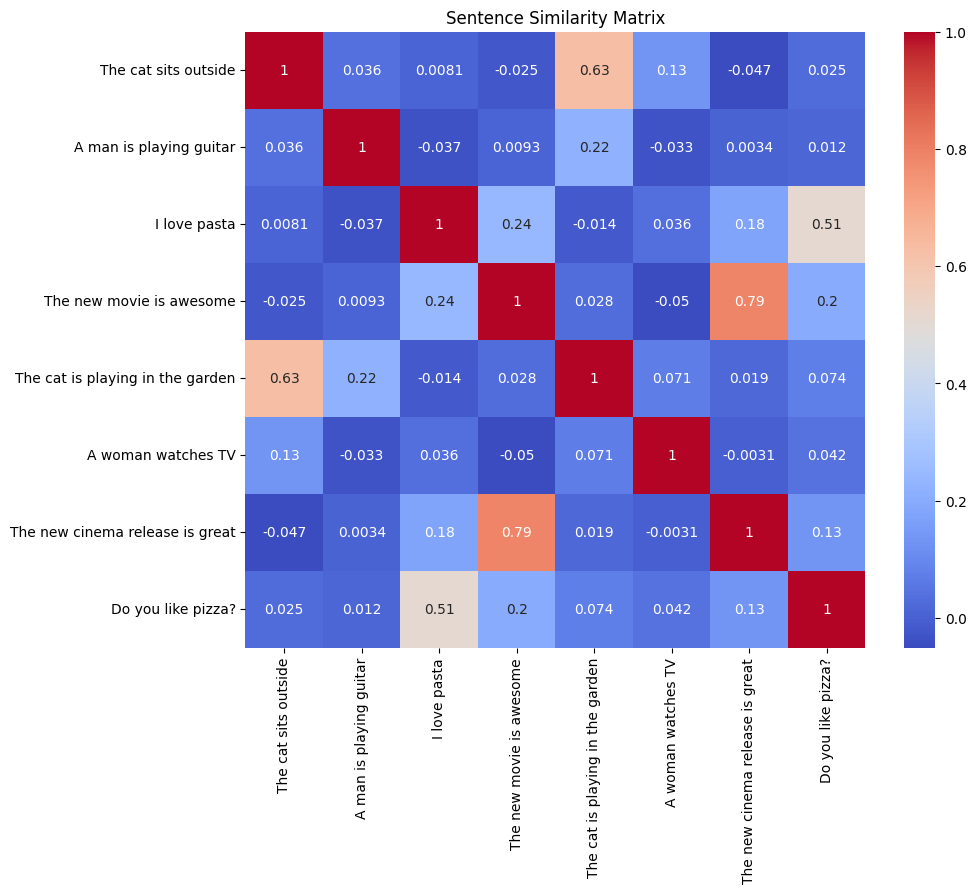

In [4]:
# Compute embeddings and similarity matrix
embeddings = sim.extract_text_embedding(sentences)

# Compute cosine similarity matrix
from sklearn.metrics.pairwise import cosine_similarity
sim_matrix = cosine_similarity(embeddings)

# Visualize
plt.figure(figsize=(10, 8))
sns.heatmap(sim_matrix, annot=True, xticklabels=sentences, yticklabels=sentences, cmap='coolwarm')
plt.title("Sentence Similarity Matrix")
plt.show()

## Semantic Search Example
Find the most similar sentence to a query.

In [5]:
query = "food is delicious"
query_embedding = sim.extract_text_embedding(query)

# Compare with all sentences
results = []
for i, sentence in enumerate(sentences):
    score = sim.compute_similarity(query_embedding, embeddings[i])
    results.append((sentence, score))

# Sort results
results.sort(key=lambda x: x[1], reverse=True)
for sent, score in results:
    print(f"{score:.4f}: {sent}")

0.4389: I love pasta
0.3777: Do you like pizza?
0.1784: The new movie is awesome
0.1442: The new cinema release is great
0.0759: The cat is playing in the garden
0.0657: A man is playing guitar
0.0458: A woman watches TV
0.0358: The cat sits outside
